# Stage 1 Baselines: VADER and Polyglot (lexicon-based)

Evaluates the two lexicon-based baselines from Cosme & De Leon (2024) under the
**same conditions** as the fine-tuned XLM-R and mBERT models (Objective 7, H01, H03):

- **Same data and preprocessing:** the Stage 1 dataset, cleaned with the study's
  `clean_text` (case normalization, repeated-character reduction, Taglish spelling map).
- **Same splits:** the same 15% held-out test set and the same 5 stratified CV folds
  (seed 42) as the Stage 1 notebooks. The notebook asserts that the holdout matches.
- **Same metrics:** accuracy, precision, recall, F1, macro/micro P/R/F1, weighted F1,
  hamming loss, per-class P/R/F1, and confusion matrices (Ch. III).
- **Same statistical test:** corrected resampled paired t-test on CV fold scores
  (macro-F1 primary, plus accuracy), as used for XLM-R vs mBERT.

**Kept from Cosme & De Leon (2024), Sec. 3.2:** reviews are translated to English
with Google Translate before scoring, because VADER only supports English and
Polyglot does not support code-switching.

**Added for this study (4 classes instead of 3):** neither tool outputs "mixed", so a
fixed rule set before any results are seen maps reviews with both positive and negative
evidence to "mixed" (see Config). It is never tuned on the data.

**Not included:** GPT-3 and GPT-3.5 (retired by OpenAI before this study's experiments).
VADER and Polyglot are sentiment-only tools, so they are Stage 1 baselines only.

**Run order:** finish both Stage 1 notebooks first. This notebook reads their fold
CSVs and test predictions. No GPU needed. The first run translates all 10,510
reviews (about 1 to 1.5 hours). It is cached and resumable, so reruns are instant.

## 1. Setup

In [24]:
!pip install -q vaderSentiment polyglot3 deep-translator scikit-learn matplotlib scipy

In [25]:
import os, re, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             hamming_loss, confusion_matrix, ConfusionMatrixDisplay)

## 2. Config (must match the Stage 1 notebooks)

In [26]:
import glob, shutil

INPUT_DIR = os.path.dirname(glob.glob("/kaggle/input/**/SentiTaglish_ProductsAndServices.csv", recursive=True)[0])
print("INPUT_DIR:", INPUT_DIR)
WORK = "/kaggle/working"
DATA_PATH = f"{INPUT_DIR}/SentiTaglish_ProductsAndServices.csv"
HOLDOUT_PATH = f"{INPUT_DIR}/holdout_test_stage1.csv"
TRANSLATION_CACHE = f"{WORK}/stage1_translated_en.csv"
RESULTS_DIR = f"{WORK}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Copy Stage 1 result CSVs into the writable folder
for f in glob.glob(f"{INPUT_DIR}/stage1_*.csv"):
    shutil.copy(f, RESULTS_DIR)

# Resume translation from an earlier session, if you uploaded the cache
if os.path.exists(f"{INPUT_DIR}/stage1_translated_en.csv") and not os.path.exists(TRANSLATION_CACHE):
    shutil.copy(f"{INPUT_DIR}/stage1_translated_en.csv", TRANSLATION_CACHE)

# Same as Stage 1
SEED = 42
TEST_SIZE = 0.15
N_FOLDS = 5
LABEL_NAMES = ["negative", "neutral", "positive", "mixed"]
LABEL2ID = {n: i for i, n in enumerate(LABEL_NAMES)}
IDS = list(range(len(LABEL_NAMES)))
SENTIMENT_CODE_MAP = {1: "negative", 2: "neutral", 3: "positive", 4: "mixed"}

# VADER: standard compound thresholds (Hutto & Gilbert, 2014)
VADER_POS_T = 0.05
VADER_NEG_T = -0.05
# Mixed rule (added for 4 classes): positive AND negative proportions both >= this
VADER_MIXED_T = 0.10

# Polyglot mixed rule: at least this many positive AND negative words
POLYGLOT_MIXED_MIN = 1

# Fine-tuned models (outputs of the Stage 1 notebooks)
FINETUNED = {
    "XLM-R": "xlm-roberta-base",
    "mBERT": "bert-base-multilingual-uncased",
}

INPUT_DIR: /kaggle/input/datasets/julianedisonyalung/thesis-stage1


## 3. Preprocessing (identical to the Stage 1 notebooks)

In [27]:
SPELLING_MAP = {
    "d2": "dito", "dto": "dito",
    "un": "yun",
    "sya": "siya", "cya": "siya",
    "nde": "hindi", "hnd": "hindi",
    "wla": "wala", "wlang": "walang",
    "eto": "ito",
    "pde": "pwede", "pwd": "pwede",
    "gud": "good",
    "thnx": "thanks", "tnx": "thanks",
    "salamt": "salamat",
}

_REPEATED_CHAR = re.compile(r"(.)\1{2,}")
_WHITESPACE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = _REPEATED_CHAR.sub(r"\1\1", text)
    tokens = text.split()
    tokens = [SPELLING_MAP.get(t, t) for t in tokens]
    text = " ".join(tokens)
    text = _WHITESPACE.sub(" ", text).strip()
    return text

## 4. Load data and rebuild the Stage 1 splits

In [28]:
df = pd.read_csv(DATA_PATH)
df["row_id"] = np.arange(len(df))
df["sentiment_label"] = df["sentiment"].map(SENTIMENT_CODE_MAP)
assert df["sentiment_label"].notna().all()
df["label"] = df["sentiment_label"].map(LABEL2ID)
df["review_clean"] = df["review"].apply(clean_text)
df = df[df["review_clean"] != ""].reset_index(drop=True)

dev_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["label"], random_state=SEED)
dev_df, test_df = dev_df.reset_index(drop=True), test_df.reset_index(drop=True)

saved = pd.read_csv(HOLDOUT_PATH)
assert sorted(saved["row_id"]) == sorted(test_df["row_id"]), "Holdout does not match Stage 1"
print(f"Holdout matches Stage 1 | Dev (CV pool): {len(dev_df)} | Held-out test: {len(test_df)}")

Holdout matches Stage 1 | Dev (CV pool): 8933 | Held-out test: 1577


## 5. Translate to English (Cosme & De Leon, 2024)

Translates the cleaned text of every review once. Progress is saved every 50
reviews, so if Google rate-limits you, just rerun this cell and it resumes.

In [29]:
import torch
from transformers import MarianMTModel, MarianTokenizer

MT_MODEL = "Helsinki-NLP/opus-mt-tl-en"
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = MarianTokenizer.from_pretrained(MT_MODEL)
mt = MarianMTModel.from_pretrained(MT_MODEL).to(device).eval()

all_df = pd.concat([dev_df, test_df], ignore_index=True)
cache = pd.read_csv(TRANSLATION_CACHE) if os.path.exists(TRANSLATION_CACHE) else pd.DataFrame(columns=["row_id", "review_en"])
todo = all_df[~all_df["row_id"].isin(set(cache["row_id"]))]
print(f"Cached: {len(cache)} | To translate: {len(todo)} | device: {device}")

BATCH = 64
ids, texts = todo["row_id"].tolist(), todo["review_clean"].tolist()
for start in range(0, len(texts), BATCH):
    batch = texts[start:start + BATCH]
    enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
    with torch.no_grad():
        out = mt.generate(**enc, max_length=256, num_beams=4)
    en_batch = tok.batch_decode(out, skip_special_tokens=True)
    pd.DataFrame({"row_id": ids[start:start + BATCH], "review_en": en_batch}).to_csv(
        TRANSLATION_CACHE, mode="a", header=not os.path.exists(TRANSLATION_CACHE), index=False)
    if (start // BATCH) % 20 == 0:
        print(f"  {start + len(batch)}/{len(texts)} translated")

cache = pd.read_csv(TRANSLATION_CACHE).drop_duplicates("row_id", keep="last")
en = dict(zip(cache["row_id"], cache["review_en"].fillna("")))
dev_df["review_en"] = dev_df["row_id"].map(en)
test_df["review_en"] = test_df["row_id"].map(en)
assert dev_df["review_en"].notna().all() and test_df["review_en"].notna().all()
print(test_df[["review_clean", "review_en"]].head(10).to_string())

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/834k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.32M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Cached: 0 | To translate: 10510 | device: cuda
  64/10510 translated
  1344/10510 translated
  2624/10510 translated
  3904/10510 translated
  5184/10510 translated
  6464/10510 translated
  7744/10510 translated
  9024/10510 translated
  10304/10510 translated
                                                                                                                                                                                                                                                                           review_clean                                                                                                                                                                                                                                                                          review_en
0                                                                                                                                                                                      

## 6. VADER

In [30]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

def vader_label(text):
    s = vader.polarity_scores(text)
    if s["pos"] >= VADER_MIXED_T and s["neg"] >= VADER_MIXED_T:
        return "mixed"
    if s["compound"] >= VADER_POS_T:
        return "positive"
    if s["compound"] <= VADER_NEG_T:
        return "negative"
    return "neutral"

for d in (dev_df, test_df):
    d["pred_vader"] = d["review_en"].apply(vader_label)
print(test_df["pred_vader"].value_counts())

pred_vader
positive    685
negative    359
neutral     311
mixed       222
Name: count, dtype: int64


## 7. Polyglot

Downloads the English sentiment lexicon once (`sentiment2.en`). Each word is
scored +1, 0, or -1.

In [31]:
from polyglot3.downloader import downloader
from polyglot3.text import Text

ok = downloader.download("sentiment2.en", quiet=True)
assert ok, "Polyglot lexicon download failed. Check your internet connection and rerun."

def polyglot_label(text):
    if not isinstance(text, str) or not text.strip():
        return "neutral"
    try:
        pols = [w.polarity for w in Text(text, hint_language_code="en").words]
    except Exception:
        return "neutral"
    n_pos = sum(p > 0 for p in pols)
    n_neg = sum(p < 0 for p in pols)
    if n_pos >= POLYGLOT_MIXED_MIN and n_neg >= POLYGLOT_MIXED_MIN:
        return "mixed"
    if n_pos > n_neg:
        return "positive"
    if n_neg > n_pos:
        return "negative"
    return "neutral"

for d in (dev_df, test_df):
    d["pred_polyglot"] = d["review_en"].apply(polyglot_label)
print(test_df["pred_polyglot"].value_counts())

pred_polyglot
positive    527
mixed       463
neutral     338
negative    249
Name: count, dtype: int64


## 8. Metrics (Ch. III)

Same metric set as the Stage 1 notebooks, plus per-class precision/recall and
hamming loss. For single-label classification, hamming loss equals 1 - accuracy
and micro-P/R/F1 equal accuracy.

In [32]:
def score(y_true, y_pred):
    y = [LABEL2ID[v] for v in y_true]
    p = [LABEL2ID[v] for v in y_pred]
    kw = dict(labels=IDS, zero_division=0)
    row = {
        "accuracy": accuracy_score(y, p),
        "macro_f1": f1_score(y, p, average="macro", **kw),
        "micro_f1": f1_score(y, p, average="micro", **kw),
        "weighted_f1": f1_score(y, p, average="weighted", **kw),
        "macro_precision": precision_score(y, p, average="macro", **kw),
        "micro_precision": precision_score(y, p, average="micro", **kw),
        "macro_recall": recall_score(y, p, average="macro", **kw),
        "micro_recall": recall_score(y, p, average="micro", **kw),
        "hamming_loss": hamming_loss(y, p),
    }
    for metric, fn in [("precision", precision_score), ("recall", recall_score), ("f1", f1_score)]:
        for name, v in zip(LABEL_NAMES, fn(y, p, average=None, **kw)):
            row[f"{metric}_{name}"] = v
    return row

## 9. Cross-validation scores (same 5 folds as Stage 1)

The lexicon tools are not trained, so each fold's score is simply the tool's
score on that fold's validation reviews. This makes them directly comparable
with the XLM-R and mBERT fold scores.

In [33]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_rows = {"vader": [], "polyglot": []}
for fold, (tr, va) in enumerate(skf.split(dev_df, dev_df["label"])):
    v = dev_df.iloc[va]
    for tag in fold_rows:
        fold_rows[tag].append({"model": tag, "fold": fold, **score(v["sentiment_label"], v[f"pred_{tag}"])})

for tag, rows in fold_rows.items():
    res = pd.DataFrame(rows)
    res.to_csv(f"{RESULTS_DIR}/stage1_{tag}_folds.csv", index=False)
    print(f"\n{tag.upper()} CV (mean, std):")
    print(res.drop(columns=["model", "fold"]).describe().loc[["mean", "std"]].round(4).T)


VADER CV (mean, std):
                      mean     std
accuracy            0.3875  0.0154
macro_f1            0.3253  0.0164
micro_f1            0.3875  0.0154
weighted_f1         0.3880  0.0144
macro_precision     0.3521  0.0155
micro_precision     0.3875  0.0154
macro_recall        0.4182  0.0352
micro_recall        0.3875  0.0154
hamming_loss        0.6125  0.0154
precision_negative  0.6003  0.0234
precision_neutral   0.0668  0.0179
precision_positive  0.4485  0.0162
precision_mixed     0.2927  0.0301
recall_negative     0.4284  0.0132
recall_neutral      0.5236  0.1138
recall_positive     0.6015  0.0265
recall_mixed        0.1191  0.0191
f1_negative         0.4999  0.0164
f1_neutral          0.1185  0.0309
f1_positive         0.5137  0.0182
f1_mixed            0.1691  0.0233

POLYGLOT CV (mean, std):
                      mean     std
accuracy            0.3562  0.0144
macro_f1            0.3167  0.0144
micro_f1            0.3562  0.0144
weighted_f1         0.3781  0.0153
macro_

## 10. Held-out test results and confusion matrices


VADER held-out test results:
accuracy              0.3773
macro_f1              0.3126
micro_f1              0.3773
weighted_f1           0.3830
macro_precision       0.3426
micro_precision       0.3773
macro_recall          0.3723
micro_recall          0.3773
hamming_loss          0.6227
precision_negative    0.5933
precision_neutral     0.0450
precision_positive    0.4438
precision_mixed       0.2883
recall_negative       0.4168
recall_neutral        0.3590
recall_positive       0.5880
recall_mixed          0.1255
f1_negative           0.4897
f1_neutral            0.0800
f1_positive           0.5058
f1_mixed              0.1749
dtype: float64


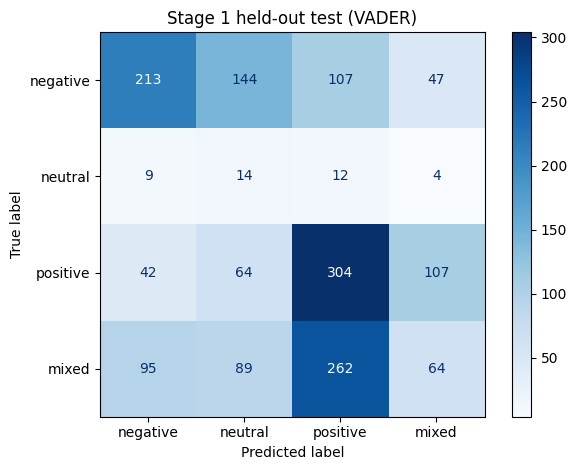


Polyglot held-out test results:
accuracy              0.3418
macro_f1              0.2981
micro_f1              0.3418
weighted_f1           0.3657
macro_precision       0.3368
micro_precision       0.3418
macro_recall          0.3454
micro_recall          0.3418
hamming_loss          0.6582
precision_negative    0.5100
precision_neutral     0.0414
precision_positive    0.4630
precision_mixed       0.3326
recall_negative       0.2485
recall_neutral        0.3590
recall_positive       0.4720
recall_mixed          0.3020
f1_negative           0.3342
f1_neutral            0.0743
f1_positive           0.4674
f1_mixed              0.3165
dtype: float64


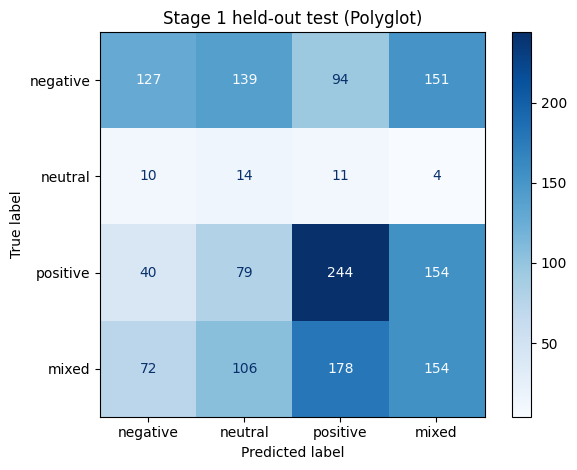

In [34]:
def save_confusion(y_true, y_pred, tag, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_NAMES)
    pd.DataFrame(cm, index=[f"true_{n}" for n in LABEL_NAMES],
                 columns=[f"pred_{n}" for n in LABEL_NAMES]).to_csv(f"{RESULTS_DIR}/stage1_{tag}_test_confusion.csv")
    ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(cmap="Blues")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/stage1_{tag}_test_confusion.png", dpi=200)
    plt.show()

for tag, title in [("vader", "VADER"), ("polyglot", "Polyglot")]:
    s = score(test_df["sentiment_label"], test_df[f"pred_{tag}"])
    pd.DataFrame([{"model": tag, **s}]).to_csv(f"{RESULTS_DIR}/stage1_{tag}_test.csv", index=False)
    out = test_df[["row_id", "review", "review_en", "sentiment_label"]].copy()
    out["pred_label"] = test_df[f"pred_{tag}"]
    out.to_csv(f"{RESULTS_DIR}/stage1_{tag}_test_predictions.csv", index=False)
    print(f"\n{title} held-out test results:")
    print(pd.Series(s).round(4))
    save_confusion(test_df["sentiment_label"], test_df[f"pred_{tag}"], tag, f"Stage 1 held-out test ({title})")

## 11. All models on the held-out test set

Recomputes every model's metrics from its saved predictions with the same
`score()` function, so all rows use identical metric code.

In [35]:
preds = {
    "Polyglot": test_df[["row_id", "sentiment_label", "pred_polyglot"]].rename(columns={"pred_polyglot": "pred_label"}),
    "VADER": test_df[["row_id", "sentiment_label", "pred_vader"]].rename(columns={"pred_vader": "pred_label"}),
}
for name, tag in FINETUNED.items():
    d = pd.read_csv(f"{RESULTS_DIR}/stage1_{tag}_test_predictions.csv")[["row_id", "sentiment_label", "pred_label"]]
    assert sorted(d["row_id"]) == sorted(test_df["row_id"]), f"{name} was not evaluated on this holdout"
    preds[name] = d

order = ["Polyglot", "VADER", "mBERT", "XLM-R"]
table = pd.DataFrame([{"model": m, **score(preds[m]["sentiment_label"], preds[m]["pred_label"])} for m in order])
table.to_csv(f"{RESULTS_DIR}/stage1_all_models_test.csv", index=False)

main_cols = ["model", "accuracy", "macro_f1", "micro_f1", "weighted_f1",
             "macro_precision", "macro_recall", "hamming_loss"]
print("Overall:")
print(table[main_cols].round(4).to_string(index=False))
for metric in ["precision", "recall", "f1"]:
    print(f"\nPer-class {metric}:")
    print(table[["model"] + [f"{metric}_{n}" for n in LABEL_NAMES]].round(4).to_string(index=False))

Overall:
   model  accuracy  macro_f1  micro_f1  weighted_f1  macro_precision  macro_recall  hamming_loss
Polyglot    0.3418    0.2981    0.3418       0.3657           0.3368        0.3454        0.6582
   VADER    0.3773    0.3126    0.3773       0.3830           0.3426        0.3723        0.6227
   mBERT    0.8155    0.6571    0.8155       0.8110           0.6791        0.6506        0.1845
   XLM-R    0.8396    0.7066    0.8396       0.8362           0.7390        0.6928        0.1604

Per-class precision:
   model  precision_negative  precision_neutral  precision_positive  precision_mixed
Polyglot              0.5100             0.0414              0.4630           0.3326
   VADER              0.5933             0.0450              0.4438           0.2883
   mBERT              0.8496             0.2500              0.8801           0.7368
   XLM-R              0.8535             0.4211              0.9038           0.7776

Per-class recall:
   model  recall_negative  recall_neutra

In [36]:
# Reference only: Cosme & De Leon (2024), Table 4. Different task (3 classes, no
# "mixed") and a different test split, so not directly comparable.
cosme = pd.DataFrame({
    "model": ["Polyglot", "VADER", "mBERT", "XLM-R", "GPT-3", "GPT-3.5"],
    "accuracy": [0.51, 0.57, 0.82, 0.84, 0.77, 0.74],
    "weighted_f1": [0.49, 0.50, 0.82, 0.84, 0.78, 0.71],
})
print("Cosme & De Leon (2024), 3-class FiReCS, for reference:")
print(cosme.to_string(index=False))

Cosme & De Leon (2024), 3-class FiReCS, for reference:
   model  accuracy  weighted_f1
Polyglot      0.51         0.49
   VADER      0.57         0.50
   mBERT      0.82         0.82
   XLM-R      0.84         0.84
   GPT-3      0.77         0.78
 GPT-3.5      0.74         0.71


## 12. Hypothesis tests: XLM-R vs each baseline (H01, H03)

Same method as the XLM-R vs mBERT comparison: corrected resampled paired t-test
(Nadeau & Bengio, 2003) on the 5 CV fold scores. Macro-F1 is the primary metric;
accuracy and weighted-F1 are also tested (H03 covers macro-F1 and accuracy).
Holm correction is applied across the three baselines for each metric.

In [37]:
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p

def holm(pvals):
    p = np.asarray(pvals); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        adj[idx] = running
    return adj

N_TEST = round(len(dev_df) / N_FOLDS)      # 1787
N_TRAIN = len(dev_df) - N_TEST              # 7146

folds = {
    "XLM-R": pd.read_csv(f"{RESULTS_DIR}/stage1_xlm-roberta-base_folds.csv"),
    "mBERT": pd.read_csv(f"{RESULTS_DIR}/stage1_bert-base-multilingual-uncased_folds.csv"),
    "VADER": pd.read_csv(f"{RESULTS_DIR}/stage1_vader_folds.csv"),
    "Polyglot": pd.read_csv(f"{RESULTS_DIR}/stage1_polyglot_folds.csv"),
}
folds = {k: v.sort_values("fold").reset_index(drop=True) for k, v in folds.items()}

rows = []
for metric in ["macro_f1", "accuracy", "weighted_f1"]:
    block = []
    for base in ["mBERT", "VADER", "Polyglot"]:
        a, b = folds["XLM-R"][metric], folds[base][metric]
        t, p = corrected_ttest(a, b, N_TRAIN, N_TEST)
        block.append({"metric": metric, "comparison": f"XLM-R vs {base}",
                      "xlmr_mean": a.mean(), "baseline_mean": b.mean(), "t": t, "p": p})
    for r, ph in zip(block, holm([r["p"] for r in block])):
        r["p_holm"] = ph
        r["significant"] = ph < 0.05
    rows += block

tests = pd.DataFrame(rows)
tests.to_csv(f"{RESULTS_DIR}/stage1_hypothesis_tests.csv", index=False)
print(tests.round(4).to_string(index=False))

     metric        comparison  xlmr_mean  baseline_mean       t      p  p_holm  significant
   macro_f1    XLM-R vs mBERT     0.7441         0.7040  2.2613 0.0866  0.0866        False
   macro_f1    XLM-R vs VADER     0.7441         0.3253 17.1744 0.0001  0.0001         True
   macro_f1 XLM-R vs Polyglot     0.7441         0.3167 19.0875 0.0000  0.0001         True
   accuracy    XLM-R vs mBERT     0.8369         0.8143  4.3053 0.0126  0.0126         True
   accuracy    XLM-R vs VADER     0.8369         0.3875 24.5748 0.0000  0.0000         True
   accuracy XLM-R vs Polyglot     0.8369         0.3562 27.8864 0.0000  0.0000         True
weighted_f1    XLM-R vs mBERT     0.8364         0.8141  3.9822 0.0164  0.0164         True
weighted_f1    XLM-R vs VADER     0.8364         0.3880 24.4371 0.0000  0.0000         True
weighted_f1 XLM-R vs Polyglot     0.8364         0.3781 24.7095 0.0000  0.0000         True
